# Lab 2: Naive Bayes Classifier
In this lab, we will predict whether a user will make a purchase based on the information provided during their online session on an e-commerce website. 


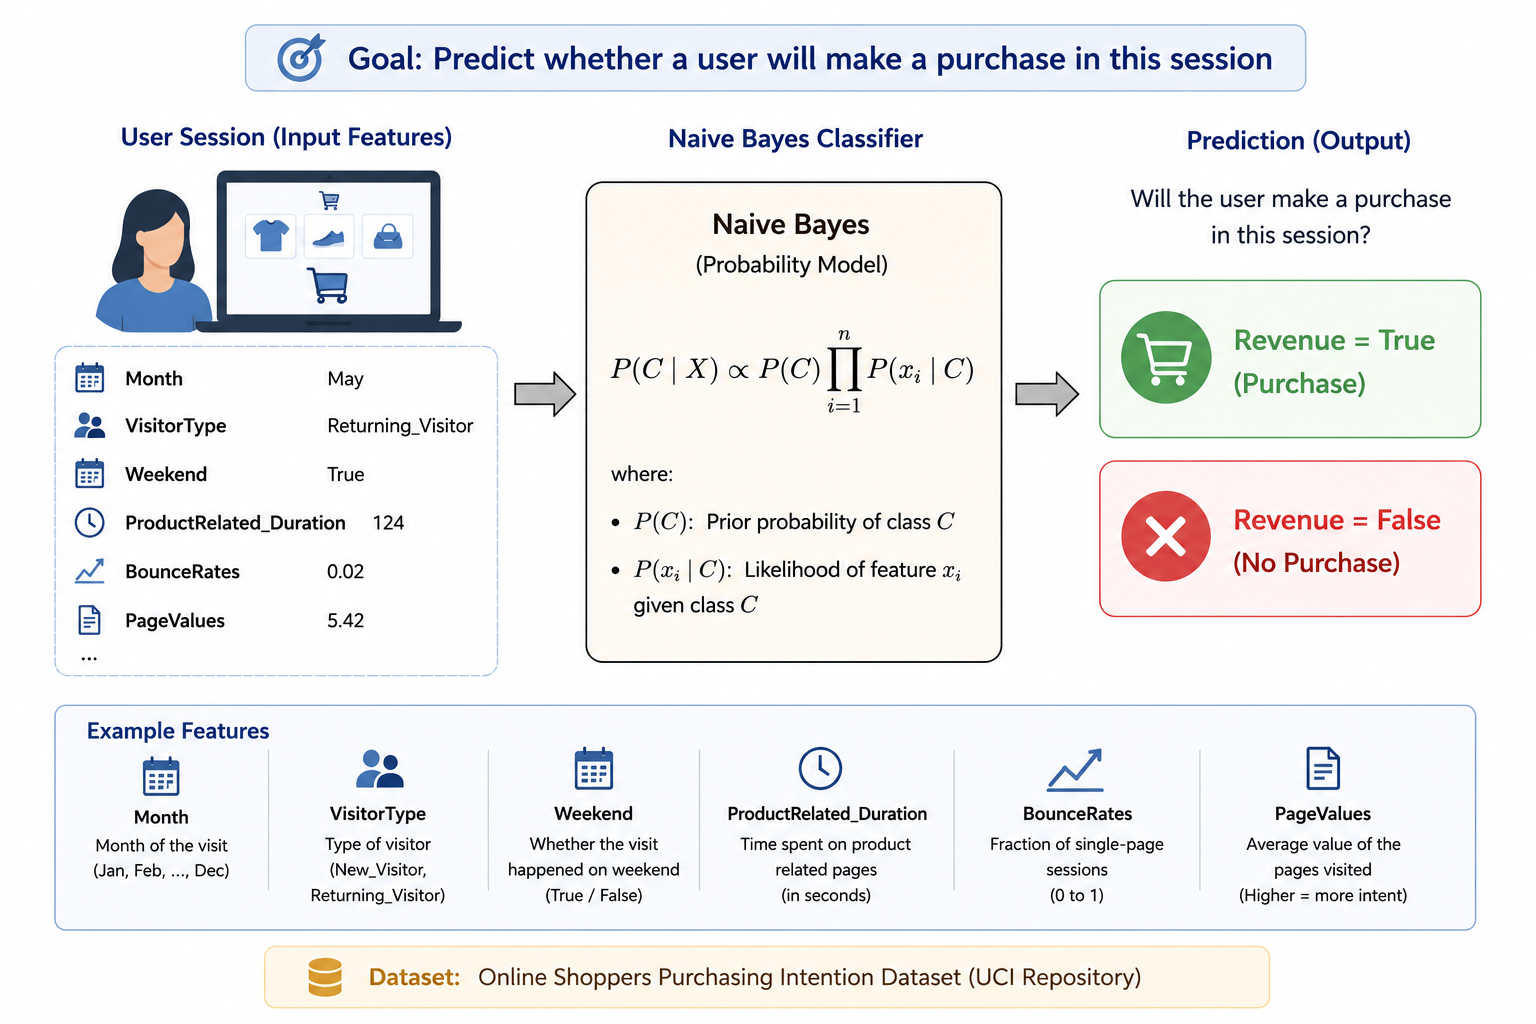



We will use the [Online Purchasing Intention Dataset](https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset). You will work with both categorical and numerical features to make your predictions. Some information about the dataset is given below:

The table below summarizes the features used in this lab.

| Feature | Type | Possible Values / Range | What it represents |
|---|---|---|---|
| `Month` | Categorical | `Jan`, `Feb`, ..., `Dec` | The month in which the online shopping session happened. |
| `VisitorType` | Categorical | `New_Visitor`, `Returning_Visitor`, `Other` | The type of visitor. A returning visitor has visited the website before, while a new visitor has not. |
| `Weekend` | Categorical / Boolean | `True`, `False` | Whether the session happened on a weekend. |
| `ProductRelated_Duration` | Numerical | Non-negative real number | Total time, in seconds, that the user spent on product-related pages during the session. |
| `BounceRates` | Numerical | Real number between `0` and `1` | The fraction of single-page visits related to the pages visited in the session. A higher value usually indicates lower engagement. |
| `PageValues` | Numerical | Non-negative real number | The average value of the pages visited by the user before completing a transaction. A higher value may indicate stronger purchase intent. |
| `Revenue` | Class Label | `True`, `False` | The target value we want to predict. `True` means the session ended with a purchase, while `False` means it did not. |

Some explanations for `BounceRates` and `PageValues`:
### Bounce Rates:
Bounce Rate is the proportion of visitors who leave a website after viewing only one page.

A high bounce rate usually means visitors are not engaging with the website. They leave without exploring further pages. As a result, sessions with higher bounce rates are often less likely to end in a purchase.
### Page Values:
Page Value measures how much a webpage contributes to a purchase.

Pages that are frequently visited before a purchase receive higher values. Therefore, a higher page value usually indicates stronger purchase intent and a greater likelihood that the session will result in a purchase.

Each row in the dataset represents a single online session. Therefore, BounceRates and PageValues describe user behavior during that particular session.

Please download the train dataset and the test dataset, which have already been prepared for you and are labelled X_train.csv, y_train.csv, X_test.csv, y_test.csv

In [ ]:
import pandas as pd
import numpy as np
from pandas import DataFrame


# Tasks

In this lab, you will build a Naive Bayes classifier to predict the `Revenue` label using the six features described above.

## Important Note:

Note on Class Imbalance: The dataset is imbalanced, with approximately 85% of sessions belonging to the Revenue=False class and 15% belonging to the Revenue=True class. As a result, accuracy alone may not fully reflect model performance, since a classifier can achieve high accuracy by predicting the majority class most of the time.


## Task 1: Convert Categorical Data to Numerical Values
Implement: `pandas_to_numpy_features(df)` and `pandas_to_numpy_revenue(df)` to convert categorical values into integer codes.

Return types:
- `pandas_to_numpy_features(df)` should return a NumPy array `np.ndarray` of shape $(n, 6)$.
- `pandas_to_numpy_revenue(df)` should return a NumPy array `np.ndarray` of shape $(n,)$ containing integer labels in $\{0, 1\}$.

Mapping rules:
- `Month`: `Jan` $\mapsto 0$, `Feb` $\mapsto 1$, `Mar` $\mapsto 2$, `Apr` $\mapsto 3$, `May` $\mapsto 4$, `June` $\mapsto 5$, `Jul` $\mapsto 6$, `Aug` $\mapsto 7$, `Sep` $\mapsto 8$, `Oct` $\mapsto 9$, `Nov` $\mapsto 10$, `Dec` $\mapsto 11$
- `VisitorType`: `Returning_Visitor` $\mapsto 0$, `New_Visitor` $\mapsto 1$, `Other` $\mapsto 2$
- `Weekend`: `False` $\mapsto 0$, `True` $\mapsto 1$
- `Revenue`: `False` $\mapsto 0$, `True` $\mapsto 1$

The returned feature matrix should contain the six features in NumPy format.

A function that you may find useful is [`Series.map()`]("https://pandas.pydata.org/docs/reference/api/pandas.Series.map.html"). 

**Important Note:** For the first function, please return all feature columns except "Revenue". For the second function, only return the new mapped "Revenue" column. Also, **for the raw dataset**, please be aware that the fields for Month and VisitorType contain strings, whereas Revenue and Weekend have boolean types. 

**Expected Output:**

X_train_np:

 [[4.00000000e+00 1.00000000e+00 0.00000000e+00 2.40000000e+01
 
  0.00000000e+00 0.00000000e+00]
  
 [4.00000000e+00 0.00000000e+00 1.00000000e+00 2.10000000e+01
 
  0.00000000e+00 0.00000000e+00]
  
 [4.00000000e+00 0.00000000e+00 1.00000000e+00 4.57583333e+02
 
  2.22222220e-02 0.00000000e+00]]
  
y_train_np:

 [0 0 0]
 
X_test_np:

 [[1.00000000e+01 0.00000000e+00 0.00000000e+00 2.61868106e+03
 
  5.79710100e-03 1.76093930e+01]
  
 [1.10000000e+01 0.00000000e+00 0.00000000e+00 6.94516667e+02
 
  8.16326500e-03 0.00000000e+00]
  
 [1.00000000e+01 0.00000000e+00 1.00000000e+00 1.54459524e+03
 
  5.85507250e-02 0.00000000e+00]]
  

In [ ]:
def pandas_to_numpy_features(df: DataFrame) -> np.ndarray:
    """Convert the feature DataFrame into a NumPy array.

    Categorical columns (Month, VisitorType, Weekend) should be mapped to
    integer codes according to the mapping rules in Task 1, while the
    numerical columns (ProductRelated_Duration, BounceRates, PageValues)
    are passed through unchanged.

    Args:
        df (DataFrame): DataFrame containing the six feature columns
            "Month", "VisitorType", "Weekend", "ProductRelated_Duration",
            "BounceRates", "PageValues". "Month" and "VisitorType" hold
            strings, "Weekend" holds booleans, and the remaining columns
            hold numeric values.

    Returns:
        np.ndarray: Array of shape (n, 6) containing the six features in
            the same column order, with Month/VisitorType/Weekend
            converted to integer codes.

    TODO:
    - Map Month, VisitorType, and Weekend to integer codes.
    - Return the six feature columns as a NumPy array with shape (n, 6).
    """
    MONTH = {"Jan":0, "Feb":1, "Mar":2, "Apr":3, "May":4, "June":5, "Jul":6, "Aug": 7, "Sep": 8, "Oct": 9, "Nov": 10, "Dec": 11}
    VTYPE = {"Returning_Visitor": 0, "New_Visitor":1, "Other": 2}
    
    
    df_cp = df.copy()
    df_cp["Month"] = df_cp["Month"].map(MONTH).astype(int)
    df_cp["VisitorType"] = df_cp["VisitorType"].map(VTYPE).astype(int)
    df_cp["Weekend"] = df_cp["Weekend"].astype(int)
    return np.array(df_cp)

def pandas_to_numpy_revenue(df: DataFrame) -> np.ndarray:
    """Convert the "Revenue" column into a NumPy array.

    Args:
        df (DataFrame): DataFrame containing a boolean "Revenue" column,
            where True means the session ended in a purchase and False
            means it did not.

    Returns:
        np.ndarray: Array of shape (n,) with Revenue mapped to integer
            labels in {0, 1} (False -> 0, True -> 1).

    TODO:
    - Map Revenue values to integer codes.
    - Return a NumPy array with shape (n,).
    """

    return np.array(df.astype(int)).flatten()
    

if __name__ == "__main__":
    # run the above 2 functions and produce a small expected output

    X_train = pd.read_csv("X_train.csv")
    y_train = pd.read_csv("y_train.csv")
    X_test = pd.read_csv("X_test.csv")

    X_train_np = pandas_to_numpy_features(X_train)
    y_train_np = pandas_to_numpy_revenue(y_train)
    X_test_np = pandas_to_numpy_features(X_test)

    print("X_train_np:\n", X_train_np[:3])
    print("y_train_np:\n", y_train_np[:3])
    print("X_test_np:\n", X_test_np[:3])    


## Task 2: Estimate Prior Probabilities
Implement: `estimate_priors(y_train)`.

Return type:
- `estimate_priors(y_train)` should return a NumPy array `np.ndarray` of shape $(C,)$ containing floating-point prior probabilities, where $C$ is the number of classes.

Formula:
$$
P(Y = j) = \frac{\text{count}(Y = j)}{n_{\text{train}}}
$$

No Laplace smoothing is needed for the priors.

**Expected output:**

[0.84529603 0.15470397]

In [ ]:
def estimate_priors(y_train: np.ndarray) -> np.ndarray:
    """Estimate the prior probability of each class from the training labels.

    Args:
        y_train (np.ndarray): Array of shape (n_train,) containing the
            integer class labels {0, 1} for the training set.

    Returns:
        np.ndarray: Array of shape (C,) containing the prior probability
            P(Y = j) for each class j, computed as the fraction of
            training examples belonging to that class.

    TODO:
    - Count how often each class appears in y_train.
    - Return the class probabilities as a NumPy array.
    """
    
    return np.bincount(y_train.flatten())/y_train.size

if __name__ == "__main__":
    X_train = pd.read_csv("X_train.csv")
    y_train = pd.read_csv("y_train.csv")
    X_train_np = pandas_to_numpy_features(X_train)
    y_train_np = pandas_to_numpy_revenue(y_train)

    priors = estimate_priors(y_train_np)
    print(priors)


## Task 3: Likelihood for Categorical Features
Implement: `cat_likelihood(X_train_feature, y_train, X_test_feature, alpha)` for one categorical feature using Laplace smoothing.

Return type:
- `cat_likelihood(...)` should return a NumPy array `np.ndarray` of shape $(n_{\text{test}}, C)$ containing floating-point likelihood values.

Formula:
$$
P(X_f = x \mid Y = j) = \frac{\text{count}\{X_f = x, Y = j\} + \alpha}{\text{count}\{Y = j\} + \alpha K_f}
$$

Here, $K_f$ is the number of possible categories for feature $f$.

## Restriction:
**Explicit for-loops are not allowed for this task. Please implement a vectorized solution.**

## Beware:
**A category value can appear in `X_test_feature` that never appears in `X_train_feature`.** If you size your smoothing table (e.g. the number of rows in a counts/probability array) using only `X_train_feature`, indexing it with a test-time category that's out of that range will throw an `IndexError`. Make sure $K_f$ (or however many rows your table has) accounts for the range of values in **both** the training and test data, not just training.

**Expected output:**

The expected output should be

Month Likelihoods:

 [[0.21377246 0.40117035]

 [0.14730539 0.1183355 ]

 [0.21377246 0.40117035]]

Visitor Likelihoods:

 [[0.87111857 0.76847613]

 [0.87111857 0.76847613]

 [0.87111857 0.76847613]]

Weekend Likelihoods:

 [[0.77146283 0.73756545]

 [0.77146283 0.73756545]

 [0.22853717 0.26243455]]


In [ ]:
def cat_likelihood(X_train_feature: np.ndarray, y_train_feature, X_test_feature, alpha) -> np.ndarray:
    """Estimate P(X_f = x | Y = j) for one categorical feature using Laplace smoothing.

    Args:
        X_train_feature (np.ndarray): Array of shape (n_train,) containing
            the integer-coded category values for this feature in the
            training set.
        y_train_feature (np.ndarray): Array of shape (n_train,) containing
            the integer class labels for the training set.
        X_test_feature (np.ndarray): Array of shape (n_test,) containing
            the integer-coded category values for this feature in the
            test set.
        alpha (float): Laplace smoothing parameter added to every
            category/class count.

    Returns:
        np.ndarray: Array of shape (n_test, C) where entry [i, j] is the
            Laplace-smoothed likelihood P(X_f = X_test_feature[i] | Y = j).

    TODO:
    - Compute the likelihood for each class and each test example.
    - Use Laplace smoothing with the provided alpha value.
    - Return an array with shape (n_test, C).
    """
    c_size = np.unique(y_train_feature.flatten()).size
    if X_test_feature.size ==0:
        return np.zeros((0,c_size))
    num_categories = int(max(X_train_feature.max(), X_test_feature.max())+1)
    bin_coded_feature_class = (X_train_feature * c_size + y_train_feature.flatten()).astype(int)
    count_numerator = np.bincount(bin_coded_feature_class,minlength=num_categories*c_size).reshape(num_categories,c_size) + alpha
    count_denom = np.bincount(y_train_feature.flatten()) + alpha*num_categories
    prob = count_numerator/count_denom
    return prob[X_test_feature.astype(int)]


if __name__ == "__main__":
    X_train = pd.read_csv("X_train.csv")
    y_train = pd.read_csv("y_train.csv")
    X_test = pd.read_csv("X_test.csv")

    X_train_np = pandas_to_numpy_features(X_train)
    y_train_np = pandas_to_numpy_revenue(y_train)
    X_test_np = pandas_to_numpy_features(X_test)

    alpha = 1.0
    month_likelihoods = cat_likelihood(X_train_np[:, 0], y_train_np, X_test_np[:, 0], alpha)
    visitor_likelihoods = cat_likelihood(X_train_np[:, 1], y_train_np, X_test_np[:, 1], alpha)
    weekend_likelihoods = cat_likelihood(X_train_np[:, 2], y_train_np, X_test_np[:, 2], alpha)

    print("Month Likelihoods:\n", month_likelihoods[:3])
    print("Visitor Likelihoods:\n", visitor_likelihoods[:3])
    print("Weekend Likelihoods:\n", weekend_likelihoods[:3])


## Task 4: Likelihood for Numerical Features (Gaussian)
Implement: `num_likelihood(X_train_feature, y_train, X_test_feature)` using a Gaussian distribution.

Return type:
- `num_likelihood(...)` should return a NumPy array `np.ndarray` of shape $(n_{\text{test}}, C)$ containing floating-point likelihood values.

For each class $j$, compute:
$$
\mu_j = \frac{1}{n_j} \sum_{i : y_i = j} x_i
$$
$$
\sigma_j^2 = \frac{1}{n_j} \sum_{i : y_i = j} (x_i - \mu_j)^2
$$

For numerical stability, use the regularized variance:
$$
\tilde{\sigma}_j^2 = \sigma_j^2 + \epsilon, \qquad \epsilon = 10^{-9}
$$
This avoids division by zero when all training values in a class are identical. Use \(\tilde{\sigma}_j^2\) in the Gaussian PDF below.

Then apply the Gaussian PDF:
$$
P(X_f = x \mid Y = j) = \frac{1}{\sqrt{2\pi\tilde{\sigma}_j^2}} \exp\left(-\frac{(x - \mu_j)^2}{2\tilde{\sigma}_j^2}\right)
$$

**Expected Output:**

ProductRelated_Duration Likelihoods:

 [[0.000152   0.00015883]
 
 [0.00021319 0.00014521]]
 
BounceRates Likelihoods:

 [[ 7.2270782  34.08959393]
 
 [ 7.34434363 33.02439594]]
 
PageValues Likelihoods:

 [[0.00940041 0.01107814]
 
 [0.0440877  0.0085289 ]]
 

In [ ]:
def num_likelihood(X_train_feature: np.ndarray, y_train_feature: np.ndarray, X_test_feature: np.ndarray) -> np.ndarray:
    """Estimate P(X_f = x | Y = j) for one numerical feature using a Gaussian distribution.

    For each class j, the mean and variance of the feature should be
    computed from the training examples belonging to that class, and the
    Gaussian PDF with those parameters evaluated at each test value.

    Args:
        X_train_feature (np.ndarray): Array of shape (n_train,) containing
            the values of this numerical feature in the training set.
        y_train_feature (np.ndarray): Array of shape (n_train,) containing
            the integer class labels for the training set.
        X_test_feature (np.ndarray): Array of shape (n_test,) containing
            the values of this numerical feature in the test set.

    Returns:
        np.ndarray: Array of shape (n_test, C) where entry [i, j] is the
            Gaussian likelihood P(X_f = X_test_feature[i] | Y = j).

    TODO:
    - Compute the mean and variance for each class.
    - Evaluate the Gaussian PDF for each test value.
    - Return an array with shape (n_test, C).
    """
    # Completely based on the fact that y has only two class 0 and 1
    y_train_feature = y_train_feature.flatten().astype(int)
    if X_test_feature.size ==0:
        c_size = np.unique(y_train_feature.flatten()).size
        return np.zeros((0,c_size))
    mean_denom = np.bincount(y_train_feature)
    mean = np.bincount(y_train_feature,weights=X_train_feature) / mean_denom
    dev = X_train_feature - mean[y_train_feature]
    var = (np.bincount(y_train_feature,weights=dev**2) / mean_denom) + 10**(-9)
    prob_denom = np.sqrt(var*2*np.pi)
    prob = np.exp(-(X_test_feature[:,None]-mean[None,:])**2/(var[None,:] * 2)) /prob_denom[None,:]
    return prob


if __name__ == "__main__":
    X_train = pd.read_csv("X_train.csv")
    y_train = pd.read_csv("y_train.csv")
    X_test = pd.read_csv("X_test.csv")

    X_train_np = pandas_to_numpy_features(X_train)
    y_train_np = pandas_to_numpy_revenue(y_train)
    X_test_np = pandas_to_numpy_features(X_test)

    product_related_duration_likelihoods = num_likelihood(X_train_np[:, 3], y_train_np, X_test_np[:, 3])
    bounce_rates_likelihoods = num_likelihood(X_train_np[:, 4], y_train_np, X_test_np[:, 4])
    page_values_likelihoods = num_likelihood(X_train_np[:, 5], y_train_np, X_test_np[:, 5])

    print("ProductRelated_Duration Likelihoods:\n", product_related_duration_likelihoods[:2])
    print("BounceRates Likelihoods:\n", bounce_rates_likelihoods[:2])
    print("PageValues Likelihoods:\n", page_values_likelihoods[:2])


## Task 5: Prediction
Implement: `predict(X_train, y_train, X_test, feat_type_list)`.

Return type:
- `predict(...)` should return a NumPy array `np.ndarray` of shape $(n_{\text{test}},)$ containing predicted class labels in $\{0, 1\}$.

Use log probabilities to avoid numerical underflow:
$$
\log P(Y = j \mid \mathbf{x}) \propto \log P(Y = j) + \sum_{f=1}^{d} \log P(X_f = x_f \mid Y = j)
$$

Predict the class with the highest log posterior:
$$
\hat{y} = \arg\max_j \left[\log P(Y = j) + \sum_{f=1}^{d} \log P(X_f = x_f \mid Y = j)\right]
$$

For this dataset, the feature-type list should be:
- `Month`: categorical
- `VisitorType`: categorical
- `Weekend`: categorical
- `ProductRelated_Duration`: numerical
- `BounceRates`: numerical
- `PageValues`: numerical

**Expected Output:**

Predictions:

 [1 0 0 0 0 0 0 0 0 0]


In [ ]:
def predict(X_train: np.ndarray, y_train: np.ndarray, X_test: np.ndarray, feat_type_list: list) -> np.ndarray:
    """Predict the class label for each test example using Naive Bayes.

    Combines the log prior with the log likelihood of every feature
    (categorical features via cat_likelihood, numerical features via
    num_likelihood) and picks the class with the highest log posterior.

    Args:
        X_train (np.ndarray): Array of shape (n_train, d) containing the
            training feature matrix.
        y_train (np.ndarray): Array of shape (n_train,) containing the
            integer class labels for the training set.
        X_test (np.ndarray): Array of shape (n_test, d) containing the
            test feature matrix.
        feat_type_list (list): List of length d where each entry is either
            "categorical" or "numerical", indicating how the corresponding
            column of X_train/X_test should be modeled.

    Returns:
        np.ndarray: Array of shape (n_test,) containing the predicted
            class label in {0, 1} for each test example.

    TODO:
    - Estimate the priors from the training labels.
    - Combine categorical and numerical likelihoods.
    - Use log probabilities to choose the most likely class.
    - Return predictions with shape (n_test,).
    """
    return (np.log(np.array([cat_likelihood(X_train[:,i],y_train,X_test[:,i],alpha=1) if (feat_type_list[i]=="categorical") else num_likelihood(X_train[:,i],y_train,X_test[:,i]) for i in range(len(feat_type_list))])).sum(axis=0) + np.log(estimate_priors(y_train))).argmax(axis=1)


if __name__ == "__main__":
    X_train = pd.read_csv("X_train.csv")
    y_train = pd.read_csv("y_train.csv")
    X_test = pd.read_csv("X_test.csv")

    X_train_np = pandas_to_numpy_features(X_train)
    y_train_np = pandas_to_numpy_revenue(y_train)
    X_test_np = pandas_to_numpy_features(X_test[:10]) # Use only the first 10 samples for testing

    feat_type_list = ["categorical", "categorical", "categorical", "numerical", "numerical", "numerical"]

    predictions = predict(X_train_np, y_train_np, X_test_np, feat_type_list)
    print("Predictions:\n", predictions)
